## Simulating RS like neurons with arbitrary synaptic channels

#### Ilaria Carannante
mailto: ilariac@kth.se
###### KTH, Stockholm, Sweden

This notebook contains synaptic stimulation of a neuron model with arbitrary number of synaptic channels:

\begin{equation}
I_{syn} = \sum_s g_s\,(E_s - V),
\end{equation}
and the conductances evolve as
\begin{equation}
\frac{d g_s}{dt} = -\frac{g_s}{\tau_s}
+ Q_s \sum_{n_s} \delta\!\left(t - t_{\text{spike}}(n_s)\right).
\end{equation}

In [1]:
#%matplotlib widget
import matplotlib.pyplot as plt

In [2]:
import sys
import os

# Adding the project folder to sys.path
cwd = os.getcwd()
parent_dir = os.path.abspath(os.path.join(cwd, '..'))
sys.path.append(parent_dir)
# We do this so that we can directly import files in the utils folder

In [3]:
from ntmf.neurons import setting_simulation_Brian_general, synaptic_channels_from_model, voltage_clamp_synapse, AdEx_eqs
from ntmf.network import network_creation, extracting_pop_freq_and_std, extracting_single_pop_freq_and_std
from utils.Plots_helper import *
from ntmf.config import get_input_config, get_network_config, get_params_model_SI, get_syn_info, adding_K_params, load_spike_data

### Defining duration of the simulation

In [4]:
sim_duration = 6 * b2.second
dt = 0.1 * b2.ms  # time resolution
times = b2.arange(0, sim_duration, dt)

### Setting up the neuron models

In [5]:
data_folder = '../neuron_models/AdEx'
idx = 0 # in this case only one model per cell type is provided

In [6]:
# In case you don't want the current injected to be zero
# Comment the next three lines.
stim_t_start = 0
stim_t_end = int(sim_duration)
stim_amplitude = 0 * b2.nA

# Adding a "step of current" for testing
# Comment out next three lines if you like to inject a "step current".
#stim_t_start = 2   #seconds
#stim_t_end = 5     #seconds
#stim_amplitude = 0.35 * b2.nA

stim_unit = 1. * b2.ms
stim_time = sim_duration

# Setting up the step current injection protocol
tmp_size = 2 + stim_t_end  
tmp = np.zeros((tmp_size, 1)) * b2.amp
tmp[stim_t_start: stim_t_end + 1, 0] = stim_amplitude
curr_array = b2.TimedArray(tmp, dt=1. * stim_unit).values.flatten()  # to solve the issue with dimention of the current vector
current_timed_array = b2.TimedArray(curr_array * b2.amp, dt=stim_unit)

In [7]:
#neuron_model = 'neuron_3_inputs'
neuron_model = 'neuron_4_inputs'
G = setting_simulation_Brian_general(idx = idx,
                                neuron_model = neuron_model,
                                json_file_name = os.path.join(data_folder, neuron_model + '.json'),
                                curr_inj = current_timed_array)

### Reading the synaptic-channel layout of the neuron

Everything below is driven by the channels declared in the neuron JSON (`E_1/Q_1/tau_1`, `E_2/...`), so it adapts automatically to any number of channels.

In [8]:
import json

with open(os.path.join(data_folder, neuron_model + '.json')) as fh:
    model = json.load(fh)[0][idx]['model']

channels = synaptic_channels_from_model(model)        # ordered channel specs
channel_names = [c['name'] for c in channels]         # e.g. ['1', '2', '3']

# Quantal conductance increment and reversal potential, per channel
Q     = {c['name']: model[c['Q_key']] * b2.nS for c in channels}
E_rev = {c['name']: model[c['E_key']] * b2.mV for c in channels}

print('channels   :', channel_names)
print('Q (nS)     :', {k: float(v / b2.nS) for k, v in Q.items()})
print('E_rev (mV) :', {k: float(v / b2.mV) for k, v in E_rev.items()})

channels   : ['1', '2', '3', '4']
Q (nS)     : {'1': 1.5, '2': 5.0, '3': 1.0, '4': 2.5}
E_rev (mV) : {'1': 0.0, '2': -80.0, '3': -80.0, '4': 0.0}


### Defining/Reading the external drive/input

The input config is **per channel**. A global `connections` block gives the external population size and connection probability for each channel (`N_external_k`, `conn_prob_k`), and the `channels` block gives each channel's background rate and timed stimulation windows. See `input_config_3_channels.json` or `input_config_4_channels.json`.

In [9]:
#input_config = get_input_config(json_file_name = '../config/input_config_3_channels.json')
input_config = get_input_config(json_file_name = '../config/input_config_4_channels.json')

In [10]:
input_config

{'metainfo': 'Input config file -- sim',
 'connections': {'N_external_1': 6000,
  'N_external_2': 4000,
  'N_external_3': 2000,
  'N_external_4': 2000,
  'conn_prob_1': 0.05,
  'conn_prob_2': 0.025,
  'conn_prob_3': 0.035,
  'conn_prob_4': 0.015},
 'channels': {'1': {'background_freq': 1.0,
   'stimulations': [{'t_start': 1.0, 't_end': 2.0, 'freq': 12.0}]},
  '2': {'background_freq': 0.0,
   'stimulations': [{'t_start': 2.0, 't_end': 3.0, 'freq': 10.0}]},
  '3': {'background_freq': 0.0,
   'stimulations': [{'t_start': 4.0, 't_end': 5.0, 'freq': 10.0}]},
  '4': {'background_freq': 0.0,
   'stimulations': [{'t_start': 3.0, 't_end': 4.0, 'freq': 10.0}]}},
 'units': {'t_start': 's', 't_end': 's', 'freq': 'Hz'}}

In [11]:
b2.seed(1234)  # fixing seed for reproducibility

# get_input_config may return the dict or a one-element list wrapping it
cfg = input_config[0] if isinstance(input_config, list) else input_config
connections = cfg['connections']

# Per-channel external population size and connection probability
N_external = {s: connections[f'N_external_{s}'] for s in channel_names}
conn_prob  = {s: connections[f'conn_prob_{s}']  for s in channel_names}

# One external Poisson population per synaptic channel. Each channel's rate
# profile = background level + any timed stimulation windows.
rate_arrays    = {}
poisson_groups = {}
for s in channel_names:
    ch = cfg['channels'][s]

    rate = b2.zeros(len(times)) * b2.Hz
    rate[:] = ch.get('background_freq', 0.0) * b2.Hz
    for stim in ch.get('stimulations', []):
        window = (times >= stim['t_start'] * b2.second) & (times < stim['t_end'] * b2.second)
        rate[window] = stim['freq'] * b2.Hz

    rate_arrays[s]    = b2.TimedArray(rate, dt=dt)
    poisson_groups[s] = b2.PoissonGroup(N_external[s], rates=f'rate_ch_{s}(t)')

### Connecting the external input to the neuron model

In [12]:
# Connect each channel's external Poisson drive to the matching conductance
# variable Gsyn{name}, incrementing it by that channel's quantal conductance Q_{name}.
synapses = {}
for s in channel_names:
    S = b2.Synapses(poisson_groups[s], G, on_pre=f'Gsyn{s}_post += Q_{s}')
    S.connect(p=conn_prob[s])
    synapses[s] = S

### Defining the Monitors (variables to record)

In [13]:
mon       = b2.StateMonitor(G, ['v', 'Is'] + [f'Gsyn{s}' for s in channel_names], record=True)
mon_spike = b2.SpikeMonitor(G)
mon_input = {s: b2.SpikeMonitor(poisson_groups[s]) for s in channel_names}

In [14]:
# to explore what's in the Monitor, use:
# print(dir(mon))
# or for more details
# help(mon)

### Running the simulation

In [15]:
%%time
# The channel objects live in dicts, so we build the network explicitly rather
# than relying on Brian2's magic collection of top-level variables.
run_namespace = {'current': current_timed_array}
run_namespace.update({f'rate_ch_{s}': rate_arrays[s] for s in channel_names})
run_namespace.update({f'Q_{s}': Q[s] for s in channel_names})

net = b2.Network(G, mon, mon_spike,
                 *poisson_groups.values(),
                 *synapses.values(),
                 *mon_input.values())
net.run(sim_duration, namespace=run_namespace)

CPU times: user 3.52 s, sys: 4.88 ms, total: 3.53 s
Wall time: 3.53 s


### Plotting the results

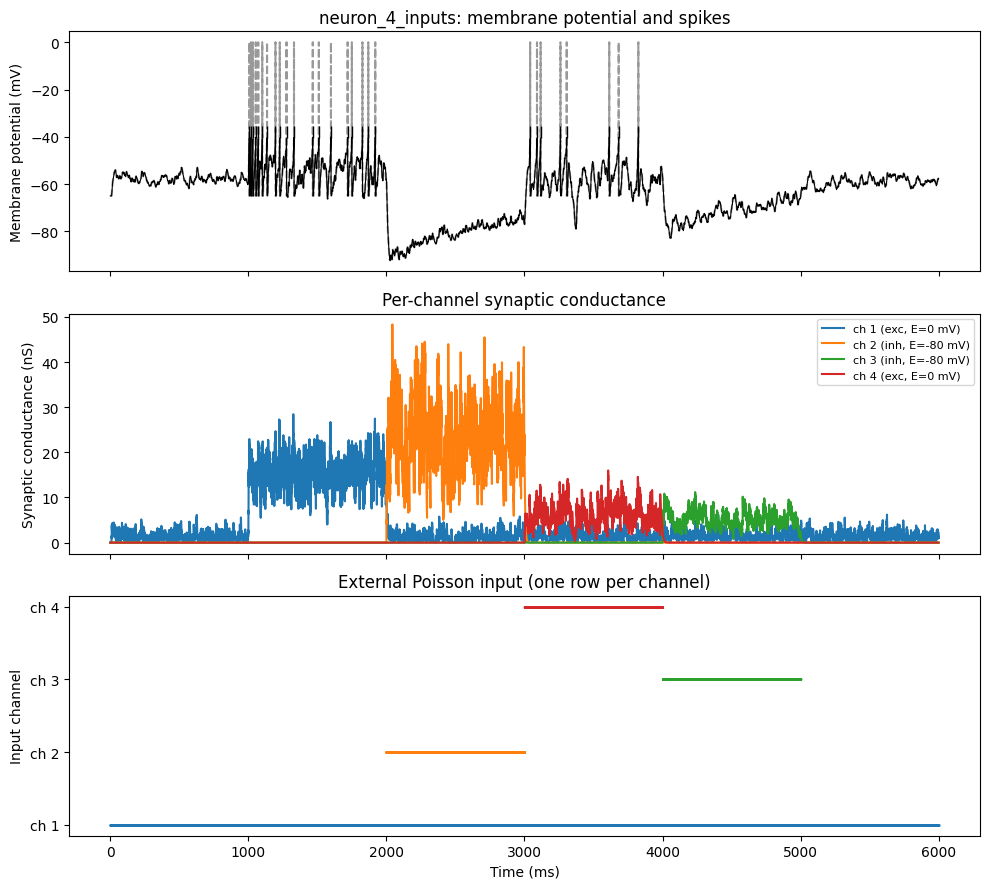

In [16]:
E_L = model['E_L'] * b2.mV
chan_colors = {s: c for s, c in zip(channel_names, plt.cm.tab10.colors)}

def chan_label(s):
    kind = 'exc' if E_rev[s] > E_L else 'inh'
    return f"ch {s} ({kind}, E={float(E_rev[s] / b2.mV):.0f} mV)"

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Membrane potential + spikes
ax[0].plot(mon.t / b2.ms, mon.v[0] / b2.mV, color='k', lw=0.8)
ax[0].plot(mon.t / b2.ms, get_pretty_voltage(mon.v[0], -45) / b2.mV, '--', color='k', alpha=0.4)
if len(mon_spike.t):
    ax[0].plot(mon_spike.t / b2.ms, np.full(len(mon_spike.t), mon.v[0].max() / b2.mV + 2),
               '|', color='k', markersize=8)
ax[0].set_ylabel('Membrane potential (mV)')
ax[0].set_title(f'{neuron_model}: membrane potential and spikes')

# Per-channel synaptic conductance
for s in channel_names:
    ax[1].plot(mon.t / b2.ms, getattr(mon, f'Gsyn{s}')[0] / b2.nS,
               color=chan_colors[s], label=chan_label(s))
ax[1].set_ylabel('Synaptic conductance (nS)')
ax[1].set_title('Per-channel synaptic conductance')
ax[1].legend(loc='upper right', fontsize=8)

# Per-channel external Poisson input raster (one row per channel)
for row, s in enumerate(channel_names):
    t_in = mon_input[s].t / b2.ms
    ax[2].plot(t_in, np.full(len(t_in), row), '.', color=chan_colors[s],
               markersize=1, alpha=0.3)
ax[2].set_yticks(range(len(channel_names)))
ax[2].set_yticklabels([f'ch {s}' for s in channel_names])
ax[2].set_ylabel('Input channel')
ax[2].set_xlabel('Time (ms)')
ax[2].set_title('External Poisson input (one row per channel)')

plt.tight_layout()

In [17]:
avg_rate = mon_spike.count[0] / sim_duration
print(f"Average firing rate: {avg_rate / b2.Hz:.2f} Hz")

Average firing rate: 4.50 Hz


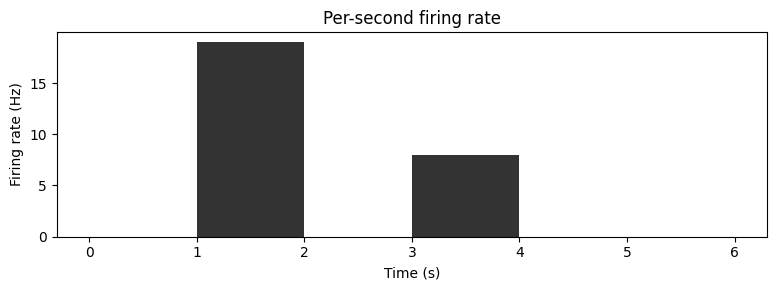

In [18]:
# Per-second firing rate of the neuron
spike_times = mon_spike.t / b2.second
bin_edges   = np.arange(0, sim_duration / b2.second + 1, 1.0)
spikes_per_bin, _ = np.histogram(spike_times, bins=bin_edges)

plt.figure(figsize=(8, 3))
plt.bar(bin_edges[:-1], spikes_per_bin, width=1.0, align='edge', color='k', alpha=0.8)
plt.xlabel('Time (s)')
plt.ylabel('Firing rate (Hz)')
plt.title('Per-second firing rate')
plt.tight_layout()